# Daily SIRD estimation across Mexico's seven epidemic phases

The ensemble Kalman filter (EnKF) estimates transmission, recovery and mortality rates from February 28, 2020 (day 0) through day 1166. The ensemble and cumulative observations carry over across every phase boundary. The phase dates come from the project metadata.

In [1]:
from functools import partial
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "Codigos":
    root = root.parent
sys.path.insert(0, str(root / "Codigos"))
from codes import gaussian_rate_walk, get_Y_obs, run_sird_enkf

DATA_DIR = root / "Datos"
SOURCE_FILE = DATA_DIR / "raw_data" / "COVID19MEXICO2020_2021_2022_2023.csv"
PHASE_FILE = DATA_DIR / "metadata" / "covid_waves_parameters.csv"
START_DATE = pd.Timestamp("2020-02-28")
LAST_DAY = 1166
END_DATE = START_DATE + pd.Timedelta(days=LAST_DAY)
CHUNK_SIZE = 250_000
POPULATION = 126_014_024
RECOVERY_DAYS = 14
SEED = 2026
ENSEMBLE_SIZE = 160
STATE_STD = np.array([1.0, 0.0, 0.0])  # People, ordered as I, R, D.
INITIAL_RATES = np.array([0.3508, 0.0714, 0.0015])  # Daily rate medians.
INITIAL_LOG_STD = np.array([0.35, 0.40, 0.50])
LOG_STEP_STD = np.array([0.12, 0.12, 0.15])  # Log-rate SD per square root of a day.
OBS_STD = np.array([10.0, 4.0, 1.5])  # Observation SDs in people, ordered as I, R, D.
OBS_COV = np.diag(OBS_STD**2)

## Phase calendar

The metadata end the sixth wave on March 31, 2023 (day 1127). April 2022 falls between the fourth and fifth waves. We retain daily observations both in that gap and from April 1 through May 9, 2023. The phase labels group results for reporting.

In [2]:
phases = pd.read_csv(PHASE_FILE, parse_dates=["Start Date", "End Date"])
dates = pd.date_range(START_DATE, END_DATE, freq="D", name="Date")
phase = pd.Series("Between waves", index=dates, name="Period")
for name, start, end in phases[["Epidemiological Phase", "Start Date", "End Date"]].itertuples(index=False, name=None):
    phase.loc[start:end] = name
phase.loc[dates > phases["End Date"].max()] = "After sixth wave"
day = np.arange(len(dates))
calendar = pd.DataFrame({"Day": day, "Period": phase}, index=dates)
periods = calendar.reset_index().groupby("Period", sort=False).agg(
    Start=("Date", "first"), End=("Date", "last"),
    First_day=("Day", "first"), Last_day=("Day", "last"), Days=("Day", "size"),
)
assert set(phases["Epidemiological Phase"]) <= set(periods.index)
print(periods.to_string())

                      Start        End  First_day  Last_day  Days
Period                                                           
Pre-lockdown     2020-02-28 2020-03-22          0        23    24
First Wave       2020-03-23 2020-09-30         24       215   192
Second Wave      2020-10-01 2021-04-30        216       427   212
Third Wave       2021-05-01 2021-11-30        428       641   214
Fourth Wave      2021-12-01 2022-03-31        642       762   121
Between waves    2022-04-01 2022-04-30        763       792    30
Fifth Wave       2022-05-01 2022-10-31        793       976   184
Sixth Wave       2022-11-01 2023-03-31        977      1127   151
After sixth wave 2023-04-01 2023-05-09       1128      1166    39


## Daily observations from individual records

We read the consolidated case file in chunks, retaining admissions within the study dates. For each chunk, `get_Y_obs` counts positive admissions, assigns recovery 14 days after admission to people without a recorded death, and counts deaths on their recorded dates. Chunk totals share one calendar, so recoveries and deaths contribute even when they occur in a later wave. The series contain active cases $I=C-R-D$, cumulative recoveries $R$ and cumulative deaths $D$.

In [3]:
columns = ["FECHA_INGRESO", "FECHA_DEF", "CLASIFICACION_FINAL"]
observed = pd.DataFrame(0, index=dates, columns=["I", "R", "D", "C"], dtype="int64")
record_counts = pd.Series(0, index=dates, dtype="int64")
with pd.read_csv(SOURCE_FILE, usecols=columns, chunksize=CHUNK_SIZE,
                 na_values={"FECHA_DEF": ["9999-99-99"]}) as reader:
    for chunk in reader:
        admission = pd.to_datetime(chunk["FECHA_INGRESO"], format="%Y-%m-%d")
        records = chunk.loc[admission.between(START_DATE, END_DATE)].copy()
        if records.empty:
            continue
        counts = admission.loc[records.index].value_counts()
        record_counts.loc[counts.index] += counts
        records["FECHA_DEF"] = pd.to_datetime(records["FECHA_DEF"], format="%Y-%m-%d")
        _, chunk_obs = get_Y_obs(records, START_DATE, END_DATE, gamma_time=RECOVERY_DAYS)
        observed += chunk_obs[observed.columns]

Y = observed[["I", "R", "D"]].to_numpy(dtype=float)
assert record_counts.gt(0).all(), "Check source coverage on days without admission records."
assert (observed["C"] == observed[["I", "R", "D"]].sum(axis=1)).all()
assert observed[["C", "R", "D"]].diff().iloc[1:].ge(0).all().all()
print(f"{record_counts.sum():,} admission records across {len(dates):,} dates.")
print(observed.loc[[START_DATE, phases["End Date"].max(), END_DATE]].to_string())

19,965,086 admission records across 1,167 dates.
                I        R       D        C
Date                                       
2020-02-28      2        0       0        2
2023-03-31  30539  7192568  333755  7556862
2023-05-09  16932  7255491  334144  7606567


## Continuous ensemble analysis

At each daily step the filter advances each member's log rates with a Gaussian random walk, integrates its SIRD equations, and assimilates the reconstructed observations. Initial rates and observation errors are working assumptions. In particular, the estimated recovery rate depends on the 14-day imputation.

In [4]:
rate_step = partial(gaussian_rate_walk, log_step_std=LOG_STEP_STD)
mean, std, parameter_paths = run_sird_enkf(
    Y, POPULATION, ensemble_size=ENSEMBLE_SIZE, state_std=STATE_STD,
    initial_rates=INITIAL_RATES, initial_log_std=INITIAL_LOG_STD,
    rate_step=rate_step, observation_cov=OBS_COV, seed=SEED, days=day,
)
assert mean.shape == std.shape == (LAST_DAY + 1, 7)
assert parameter_paths.shape == (LAST_DAY + 1, ENSEMBLE_SIZE, 3)
assert np.isfinite(mean).all() and np.isfinite(std).all()
assert np.isfinite(parameter_paths).all() and (parameter_paths > 0).all()
assert np.allclose(mean[:, :4].sum(axis=1), POPULATION, rtol=0, atol=1e-5)

## Observations and filtered estimates

The shaded bands cover one sample standard deviation on either side of the ensemble mean. Vertical lines mark phase starts. Gray backgrounds mark the April 2022 gap and the period after the sixth wave. Day ranges for each wave appear in the calendar above.

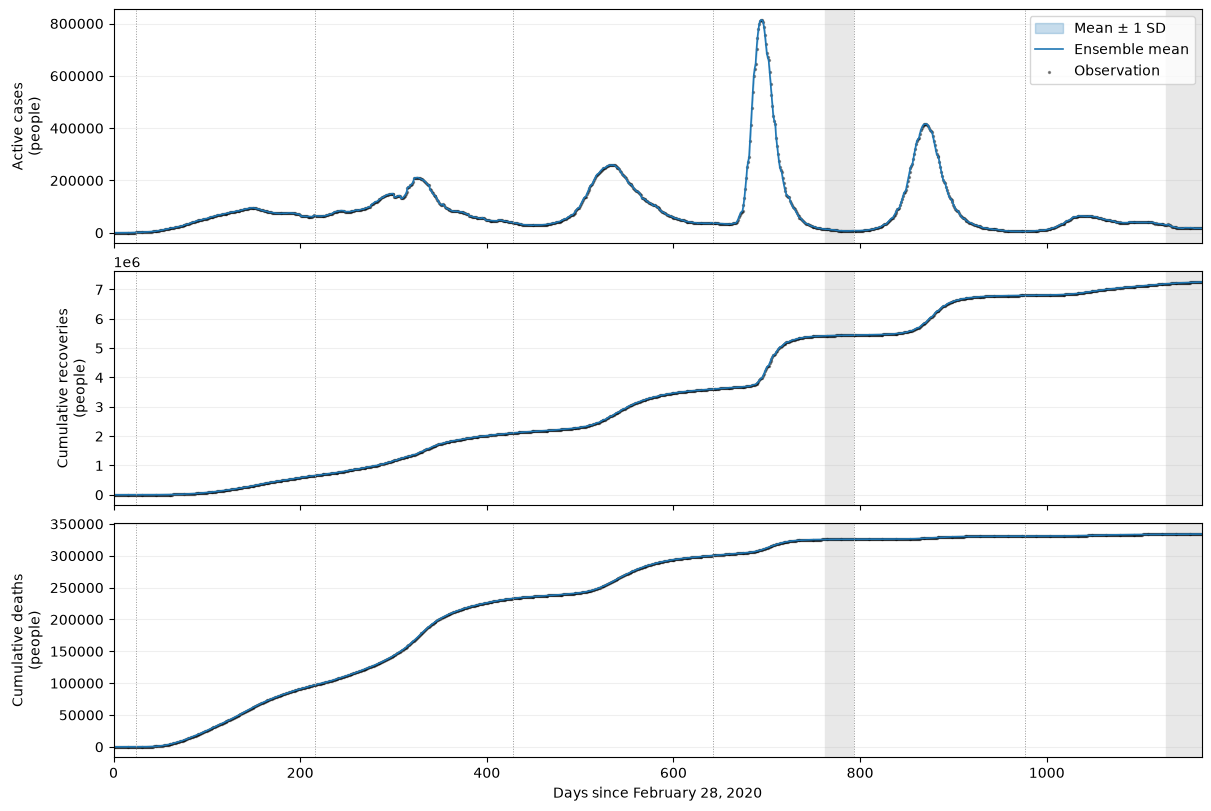

In [5]:
def mark_periods(ax):
    for start in phases["Start Date"].iloc[1:]:
        ax.axvline((start - START_DATE).days, color="0.6", linewidth=0.7, linestyle=":")
    for name in ["Between waves", "After sixth wave"]:
        if name in periods.index:
            period = periods.loc[name]
            ax.axvspan(period.First_day - 0.5, period.Last_day + 0.5,
                       color="0.91", zorder=0)
    ax.set_xlim(0, LAST_DAY)
    ax.grid(axis="y", alpha=0.2)


def plot_band(ax, column):
    center, spread = mean[:, column], std[:, column]
    ax.fill_between(day, center - spread, center + spread,
                    color="tab:blue", alpha=0.25, label="Mean ± 1 SD")
    ax.plot(day, center, color="tab:blue", linewidth=1.2, label="Ensemble mean")
    mark_periods(ax)


fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for j, (ax, label) in enumerate(zip(axes, ["Active cases", "Cumulative recoveries", "Cumulative deaths"])):
    plot_band(ax, j + 1)
    ax.scatter(day, Y[:, j], s=2, color="black", alpha=0.4, label="Observation")
    ax.set_ylabel(f"{label}\n(people)")
axes[0].legend()
axes[-1].set_xlabel("Days since February 28, 2020")
plt.show()

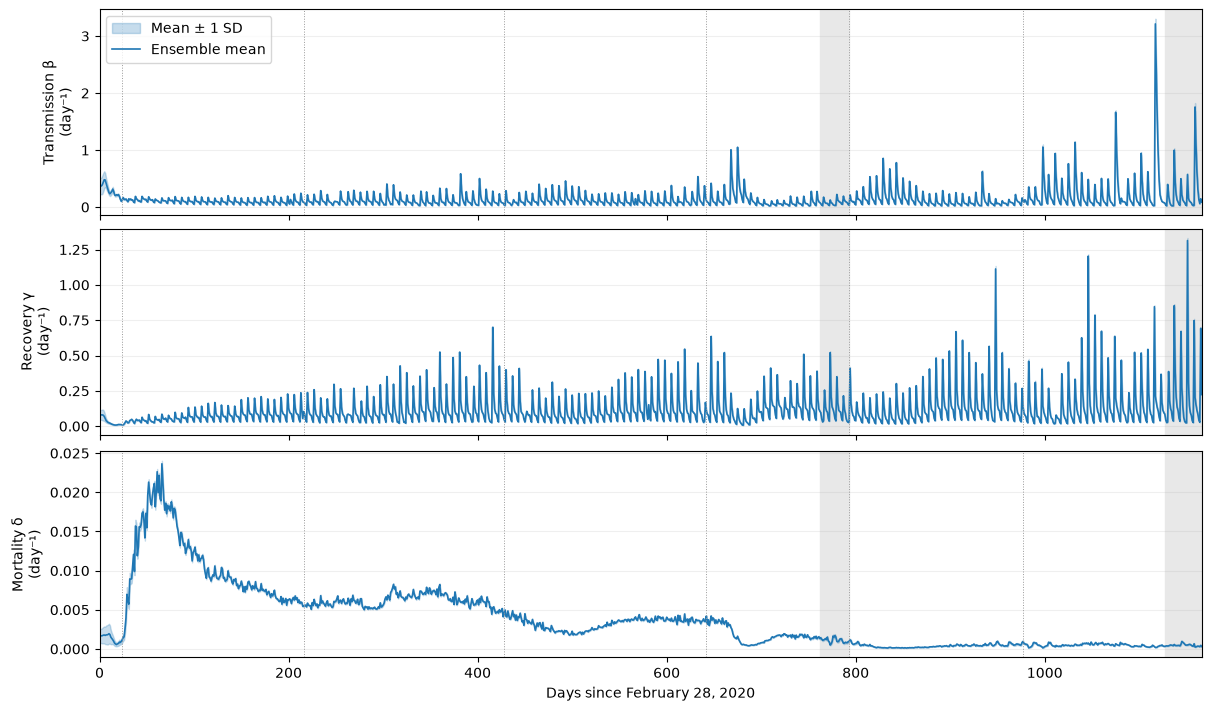

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for j, (ax, label) in enumerate(zip(axes, ["Transmission β", "Recovery γ", "Mortality δ"])):
    plot_band(ax, j + 4)
    ax.set_ylabel(f"{label}\n(day⁻¹)")
axes[0].legend()
axes[-1].set_xlabel("Days since February 28, 2020")
plt.show()

## Reproduction ratio

For each day, $R_0(t)=\bar\beta(t)/(\bar\gamma(t)+\bar\delta(t))$ uses the ensemble mean rates under full susceptibility, with rates held at that day's values. The effective reproduction number also includes the susceptible fraction $S(t)/N$. The graph shows the complete daily series, and the table reports the closing estimate for each calendar period.

             Day            Period      beta     gamma       delta       R0
Date                                                                       
2020-03-22    23      Pre-lockdown   0.10098 0.0110107 0.000953932  8.43982
2020-09-30   215        First Wave 0.0934827 0.0544546  0.00544507  1.56065
2021-04-30   427       Second Wave 0.0693712 0.0786678  0.00410957 0.838046
2021-11-30   641        Third Wave  0.189115  0.168263  0.00351808  1.10091
2022-03-31   762       Fourth Wave 0.0793475  0.106199  0.00131788    0.738
2022-04-30   792     Between waves 0.0448341 0.0269874 0.000918607  1.60661
2022-10-31   976        Fifth Wave  0.160785  0.266348 0.000835583  0.60178
2023-03-31  1127        Sixth Wave 0.0701434 0.0845625 0.000336718 0.826196
2023-05-09  1166  After sixth wave  0.087842  0.224029 0.000321336 0.391539
Final R₀ on day 1166 (2023-05-09): 0.3915


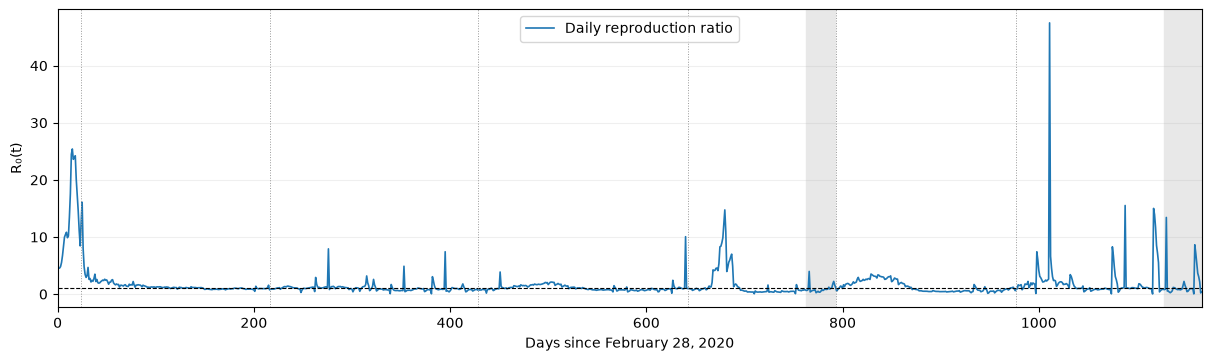

In [7]:
beta, gamma, delta = mean[:, 4:].T
r0 = beta / (gamma + delta)
results = calendar.assign(beta=beta, gamma=gamma, delta=delta, R0=r0)
closing = results.groupby("Period", sort=False).tail(1)
print(closing.to_string(float_format=lambda value: f"{value:.6g}"))
print(f"Final R₀ on day {day[-1]} ({dates[-1]:%Y-%m-%d}): {r0[-1]:.4f}")

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.plot(day, r0, linewidth=1.2, label="Daily reproduction ratio")
ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
mark_periods(ax)
ax.set(xlabel="Days since February 28, 2020", ylabel="R₀(t)")
ax.legend()
plt.show()